# 1. Cleaning

In [1]:
import numpy as np
import pandas as pd


In [2]:
df = pd.read_csv('CSV_for_ml/loan_logreg1.csv', encoding = 'utf-8')

In [3]:
pd.set_option('display.max_columns', None)
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303638 entries, 0 to 1303637
Data columns (total 52 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   is_default                   1303638 non-null  int64  
 1   loan_amnt                    1303638 non-null  int64  
 2   is_term_sixty                1303638 non-null  int64  
 3   purpose                      1303638 non-null  object 
 4   int_rate                     1303638 non-null  float64
 5   grade                        1303638 non-null  int64  
 6   is_whole_offer               1303638 non-null  int64  
 7   is_joint_application         1303638 non-null  int64  
 8   emp_length                   1228181 non-null  float64
 9   home_ownership               1303638 non-null  object 
 10  annual_inc                   1303638 non-null  int64  
 11  verification_status          1303638 non-null  object 
 12  verif_status                 1303638 non-n

In [4]:
df = df.drop(columns=['verification_status'])

In [5]:
s = df["emp_length"].value_counts(normalize=True)
missing = df['emp_length'].isnull()
df.loc[missing,'emp_length'] = np.random.choice(s.index, size=len(df[missing]),p=s.values)

In [6]:
df.head(10)

,is_default,loan_amnt,is_term_sixty,purpose,int_rate,grade,is_whole_offer,is_joint_application,emp_length,home_ownership,annual_inc,verif_status,addr_state,delinq_2yrs,inq_last_6mths,pub_rec,pub_rec_bankruptcies,total_acc,mort_acc,dti,open_acc,revol_bal,revol_util,acc_now_delinq,tot_coll_amt,tot_cur_bal,mths_since_last_delinq,mths_since_last_record,mths_since_recent_inq,mths_since_recent_bc_dlq,mths_since_last_major_derog,mths_since_rcnt_il,all_util,avg_cur_bal,bc_open_to_buy,bc_util,il_util,inq_fi,inq_last_12m,pct_tl_nvr_dlq,tax_liens,tot_hi_cred_lim,total_bal_il,total_cu_tl,total_il_high_credit_limit,total_rev_hi_lim,num_actv_bc_tl,num_bc_tl,num_sats,num_tl_op_past_12m,credit_hist_months
0,0,30000,0,debt_consolidation,22.35,4,1,1,5.0,MORTGAGE,100000,1,CA,0,0,1,1,19,1,30.46,11,15603,37.0,0,0,472330,51.0,84.0,8,NaN,NaN,2,60,42939,15181,46.9,75,1,3,89.5,0,527120,82850,1,101984,42200,3,5,11,2,83
1,0,40000,1,credit_card,16.14,5,1,1,0.0,MORTGAGE,45000,2,OH,0,0,0,0,37,1,50.53,18,34971,64.5,0,0,271068,NaN,NaN,9,NaN,NaN,5,75,15059,14930,67.3,87,4,4,100.0,0,344802,126749,2,167965,54200,7,7,18,4,114
2,0,20000,0,credit_card,7.56,7,1,1,10.0,MORTGAGE,100000,0,WA,0,0,0,0,19,5,18.92,9,25416,29.9,0,0,515779,48.0,NaN,13,NaN,NaN,13,39,57309,59684,29.9,71,2,0,94.7,0,622183,46153,2,74833,85100,5,6,9,1,238
3,0,4500,0,credit_card,11.31,6,1,0,10.0,RENT,38500,0,TX,0,0,0,0,25,0,4.64,12,4472,15.3,0,306,29137,25.0,NaN,6,NaN,25.0,3,54,2428,10735,28.9,100,0,3,91.7,0,53795,24665,3,24595,29200,3,6,12,4,180
4,0,8425,0,credit_card,27.27,3,1,1,3.0,MORTGAGE,450000,2,MA,0,0,0,0,37,4,12.37,21,36812,65.7,0,0,690320,NaN,NaN,4,NaN,NaN,12,68,34516,11632,74.6,70,7,5,100.0,0,768304,152382,0,189054,56000,6,10,21,2,254
5,0,20000,1,debt_consolidation,17.97,4,1,0,4.0,RENT,57000,0,WA,0,0,0,0,16,1,22.18,10,33356,45.9,0,0,33356,NaN,NaN,17,NaN,NaN,78,46,3336,32170,50.4,0,0,0,100.0,0,72700,0,0,0,72700,4,9,10,2,284
6,0,6600,0,credit_card,11.31,6,0,0,10.0,RENT,45000,0,TX,0,0,0,0,13,0,16.21,6,6167,58.2,0,0,26836,NaN,NaN,0,NaN,NaN,27,70,4473,4433,58.2,74,0,0,84.6,0,38607,20669,1,28007,10600,2,4,6,0,116
7,0,2500,0,other,13.56,5,0,0,5.0,RENT,42000,0,PA,0,0,0,0,6,0,15.09,3,3319,31.6,0,0,18649,53.0,NaN,12,NaN,NaN,22,57,6216,7181,31.6,69,2,1,83.3,0,32582,15330,0,22082,10500,2,2,3,1,177
8,0,4000,0,house,17.97,4,1,0,5.0,MORTGAGE,60000,1,TX,0,1,0,0,18,2,19.10,11,382,7.3,0,0,106556,38.0,NaN,2,NaN,38.0,1,72,9687,3818,9.1,77,3,3,88.2,0,127200,45868,0,59474,5200,2,5,11,4,138
9,0,2700,0,credit_card,8.19,7,0,0,4.0,OWN,24000,0,MI,0,0,1,1,28,0,24.95,21,2696,36.4,0,449,75363,NaN,94.0,18,NaN,NaN,16,97,3589,3304,44.9,103,1,0,100.0,0,78017,72667,0,70617,7400,1,4,21,0,194


In [7]:
from scipy.stats import mannwhitneyu, chi2_contingency

isdef = df[df["is_default"] == 1]
non = df[df["is_default"] == 0]

In [8]:
print(len(isdef), len(non))

261686 1041952


In [9]:
bin_features = ["is_term_sixty", "is_whole_offer", "is_joint_application"]
cat_features = ["purpose", "home_ownership", "addr_state"]
num_features = [col for col in df.columns if col not in bin_features + cat_features]

In [10]:
def rank_biserial(g1, g2, u_stat):
    # effect size for mann-whitney, ranges -1 to 1
    return 1 - (2 * u_stat) / (len(g1) * len(g2))


def cramers_v(chi2_stat, n, shape):
    min_dim = min(shape[0] - 1, shape[1] - 1)
    return np.sqrt(chi2_stat / (n * min_dim))


def run_mwu(features):
    out = []
    for f in features:
        if f not in df.columns:
            continue
        u, p = mannwhitneyu(isdef[f], non[f], nan_policy='omit', alternative="two-sided")
        out.append({
            "feature":   f,
            "isdef_mean": round(isdef[f].mean(), 4),
            "non_mean": round(non[f].mean(), 4),
            "U":         round(u, 1),
            "rank_biserial": round(rank_biserial(isdef[f], non[f], u), 4),
            "p_value":   p,
        })
    return pd.DataFrame(out)


def run_chi2_bin(features):
    n_total = len(df)
    out = []
    for f in features:
        if f not in df.columns:
            continue
        table = pd.crosstab(df["is_default"], df[f])
        chi2, p, dof, _ = chi2_contingency(table)
        out.append({
            "feature":     f,
            "isdef_rate":    round(isdef[f].mean(), 4),   # proportion flagged in isdef
            "non_rate":    round(non[f].mean(), 4),
            "chi2":        round(chi2, 2),
            "cramers_v":  round(cramers_v(chi2, n_total, table.shape), 4),
            "p_value":     f'{p:.3e}',
        })
    return pd.DataFrame(out)

def run_chi2_cat(features):
    n_total = len(df)
    out = []
    for f in features:
        if f not in df.columns:
            continue
        table = pd.crosstab(df["is_default"], df[f])
        chi2, p, dof, _ = chi2_contingency(table)
        out.append({
            "feature":    f,
            "chi2":       round(chi2, 2),
            "cramers_v":  round(cramers_v(chi2, n_total, table.shape), 4),
            "p_value":    f'{p:.3e}',
            "n_levels":   table.shape[1],
        })
    return pd.DataFrame(out)

In [11]:
pd.reset_option('float_format')

print("1. continuous features (Mann-Whitney U)")
cont_results = run_mwu(num_features)
print(cont_results.to_string(index=False), "\n")

print("2. binary features (Chi-squared)")
bin_results = run_chi2_bin(bin_features)
print(bin_results)

print("3. categorical features (Chi-squared)")
cat_results = run_chi2_cat(cat_features)
print(cat_results)

1. continuous features (Mann-Whitney U)
                    feature  isdef_mean    non_mean            U  rank_biserial       p_value
                 is_default      1.0000      0.0000 2.726643e+11        -1.0000  0.000000e+00
                  loan_amnt  15549.0091  14132.4937 1.501466e+11        -0.1013  0.000000e+00
                   int_rate     15.7122     12.6408 1.862104e+11        -0.3659  0.000000e+00
                      grade      4.5709      5.4187 8.720939e+10         0.3603  0.000000e+00
                 emp_length      5.8674      5.9938 1.336045e+11         0.0200  3.354512e-59
                 annual_inc  70327.2754  77623.3265 1.230506e+11         0.0974  0.000000e+00
               verif_status      1.1524      0.9766 1.529311e+11        -0.1218  0.000000e+00
                delinq_2yrs      0.3527      0.3088 1.389997e+11        -0.0196 8.441298e-113
             inq_last_6mths      0.7813      0.6284 1.476539e+11        -0.0830  0.000000e+00
                    

In [12]:
# bonferroni correction
n_tests = len(cont_results) + len(bin_results) + len(cat_results)
alpha_adj = 0.05 / n_tests
print(f"tests run: {n_tests}")
print(f"bonferroni-adjusted alpha: {round(alpha_adj, 5)}")
print("(features below this p-value are significant after correction)")

tests run: 51
bonferroni-adjusted alpha: 0.00098
(features below this p-value are significant after correction)


In [13]:
def level_summary(df, f, target="is_default"):
    table = pd.crosstab(df[f], df[target])          # columns: 0, 1
    chi2, p, dof, expected = chi2_contingency(table)
    N = table.values.sum()
    row_tot = table.sum(axis=1).values
    col_tot = table.sum(axis=0).values

    obs_def = table[1].values
    exp_def = expected[:, 1]
    adj_resid = (obs_def - exp_def) / np.sqrt(
        exp_def * (1 - row_tot / N) * (1 - col_tot[1] / N)
    )

    overall = df[target].mean()
    out = pd.DataFrame({
        "n": row_tot,
        "default_rate": obs_def / row_tot,
        "lift": (obs_def / row_tot) / overall,
        "adj_resid": adj_resid,
    }, index=table.index)
    return out.sort_values("default_rate", ascending=False).round(4)


In [14]:
for f in ["purpose", "home_ownership", "addr_state"]:
    display(level_summary(df, f))

,n,default_rate,lift,adj_resid
purpose,,,,
small_business,15010,0.2975,1.4819,29.7594
renewable_energy,911,0.2371,1.1812,2.7413
moving,9173,0.2345,1.1682,8.1003
medical,15024,0.2191,1.0916,5.6574
house,6967,0.2172,1.0819,3.4333
debt_consolidation,757610,0.2126,1.0590,39.7942
other,74937,0.2117,1.0548,7.7454
vacation,8732,0.1924,0.9585,-1.9521
major_purchase,28328,0.1872,0.9327,-5.7353


,n,default_rate,lift,adj_resid
home_ownership,,,,
RENT,517821,0.2335,1.1632,75.8057
OWN,139849,0.2075,1.0336,6.6657
ANY,267,0.1948,0.9702,-0.2439
OTHER,144,0.1875,0.9341,-0.3965
MORTGAGE,645509,0.1730,0.8618,-78.2890
NONE,48,0.1458,0.7265,-0.9496


,n,default_rate,lift,adj_resid
addr_state,,,,
MS,6316,0.2620,1.3054,12.1917
NE,3422,0.2542,1.2665,7.8239
AR,9708,0.2417,1.2039,10.1037
AL,16130,0.2374,1.1826,11.6929
OK,11846,0.2371,1.1813,9.9336
LA,15021,0.2341,1.1661,10.2598
NY,106387,0.2215,1.1033,17.6224
NV,19652,0.2205,1.0986,6.9832
IN,21020,0.2161,1.0767,5.6169


In [15]:
df

,is_default,loan_amnt,is_term_sixty,purpose,int_rate,grade,is_whole_offer,is_joint_application,emp_length,home_ownership,annual_inc,verif_status,addr_state,delinq_2yrs,inq_last_6mths,pub_rec,pub_rec_bankruptcies,total_acc,mort_acc,dti,open_acc,revol_bal,revol_util,acc_now_delinq,tot_coll_amt,tot_cur_bal,mths_since_last_delinq,mths_since_last_record,mths_since_recent_inq,mths_since_recent_bc_dlq,mths_since_last_major_derog,mths_since_rcnt_il,all_util,avg_cur_bal,bc_open_to_buy,bc_util,il_util,inq_fi,inq_last_12m,pct_tl_nvr_dlq,tax_liens,tot_hi_cred_lim,total_bal_il,total_cu_tl,total_il_high_credit_limit,total_rev_hi_lim,num_actv_bc_tl,num_bc_tl,num_sats,num_tl_op_past_12m,credit_hist_months
0,0,30000,0,debt_consolidation,22.35,4,1,1,5.0,MORTGAGE,100000,1,CA,0,0,1,1,19,1,30.46,11,15603,37.0,0,0,472330,51.0,84.0,8,NaN,NaN,2,60,42939,15181,46.9,75,1,3,89.5,0,527120,82850,1,101984,42200,3,5,11,2,83
1,0,40000,1,credit_card,16.14,5,1,1,0.0,MORTGAGE,45000,2,OH,0,0,0,0,37,1,50.53,18,34971,64.5,0,0,271068,NaN,NaN,9,NaN,NaN,5,75,15059,14930,67.3,87,4,4,100.0,0,344802,126749,2,167965,54200,7,7,18,4,114
2,0,20000,0,credit_card,7.56,7,1,1,10.0,MORTGAGE,100000,0,WA,0,0,0,0,19,5,18.92,9,25416,29.9,0,0,515779,48.0,NaN,13,NaN,NaN,13,39,57309,59684,29.9,71,2,0,94.7,0,622183,46153,2,74833,85100,5,6,9,1,238
3,0,4500,0,credit_card,11.31,6,1,0,10.0,RENT,38500,0,TX,0,0,0,0,25,0,4.64,12,4472,15.3,0,306,29137,25.0,NaN,6,NaN,25.0,3,54,2428,10735,28.9,100,0,3,91.7,0,53795,24665,3,24595,29200,3,6,12,4,180
4,0,8425,0,credit_card,27.27,3,1,1,3.0,MORTGAGE,450000,2,MA,0,0,0,0,37,4,12.37,21,36812,65.7,0,0,690320,NaN,NaN,4,NaN,NaN,12,68,34516,11632,74.6,70,7,5,100.0,0,768304,152382,0,189054,56000,6,10,21,2,254
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1303633,1,30000,1,debt_consolidation,17.09,4,0,0,2.0,RENT,80000,0,NY,0,1,0,0,69,0,23.22,21,19224,30.8,0,0,196622,46.0,NaN,2,NaN,61.0,8,61,9831,31294,36.5,101,0,1,54.9,0,231009,177398,0,168609,62400,5,8,21,3,190
1303634,1,18000,1,debt_consolidation,30.65,2,1,0,10.0,MORTGAGE,77000,2,TX,0,1,0,0,15,1,8.08,9,10100,45.1,0,265,324621,38.0,NaN,4,38.0,NaN,4,59,36069,7083,48.7,98,0,7,93.3,0,338546,6925,3,7058,22400,3,4,9,5,157
1303635,0,17950,1,debt_consolidation,30.17,2,0,0,10.0,MORTGAGE,53758,1,IL,0,1,1,1,24,3,33.24,11,5959,35.9,0,0,156247,NaN,80.0,0,NaN,NaN,11,46,15625,1587,60.3,49,1,2,100.0,0,203667,30693,1,63002,16600,1,4,11,2,202
1303636,0,15000,1,debt_consolidation,16.02,5,1,0,0.0,RENT,85000,2,NY,0,3,0,0,87,1,14.66,19,6988,24.8,0,4199,239081,36.0,NaN,0,36.0,36.0,4,52,17077,17477,23.7,70,1,7,89.0,0,267274,232093,2,239074,28200,4,17,19,7,199


# 2. EDA

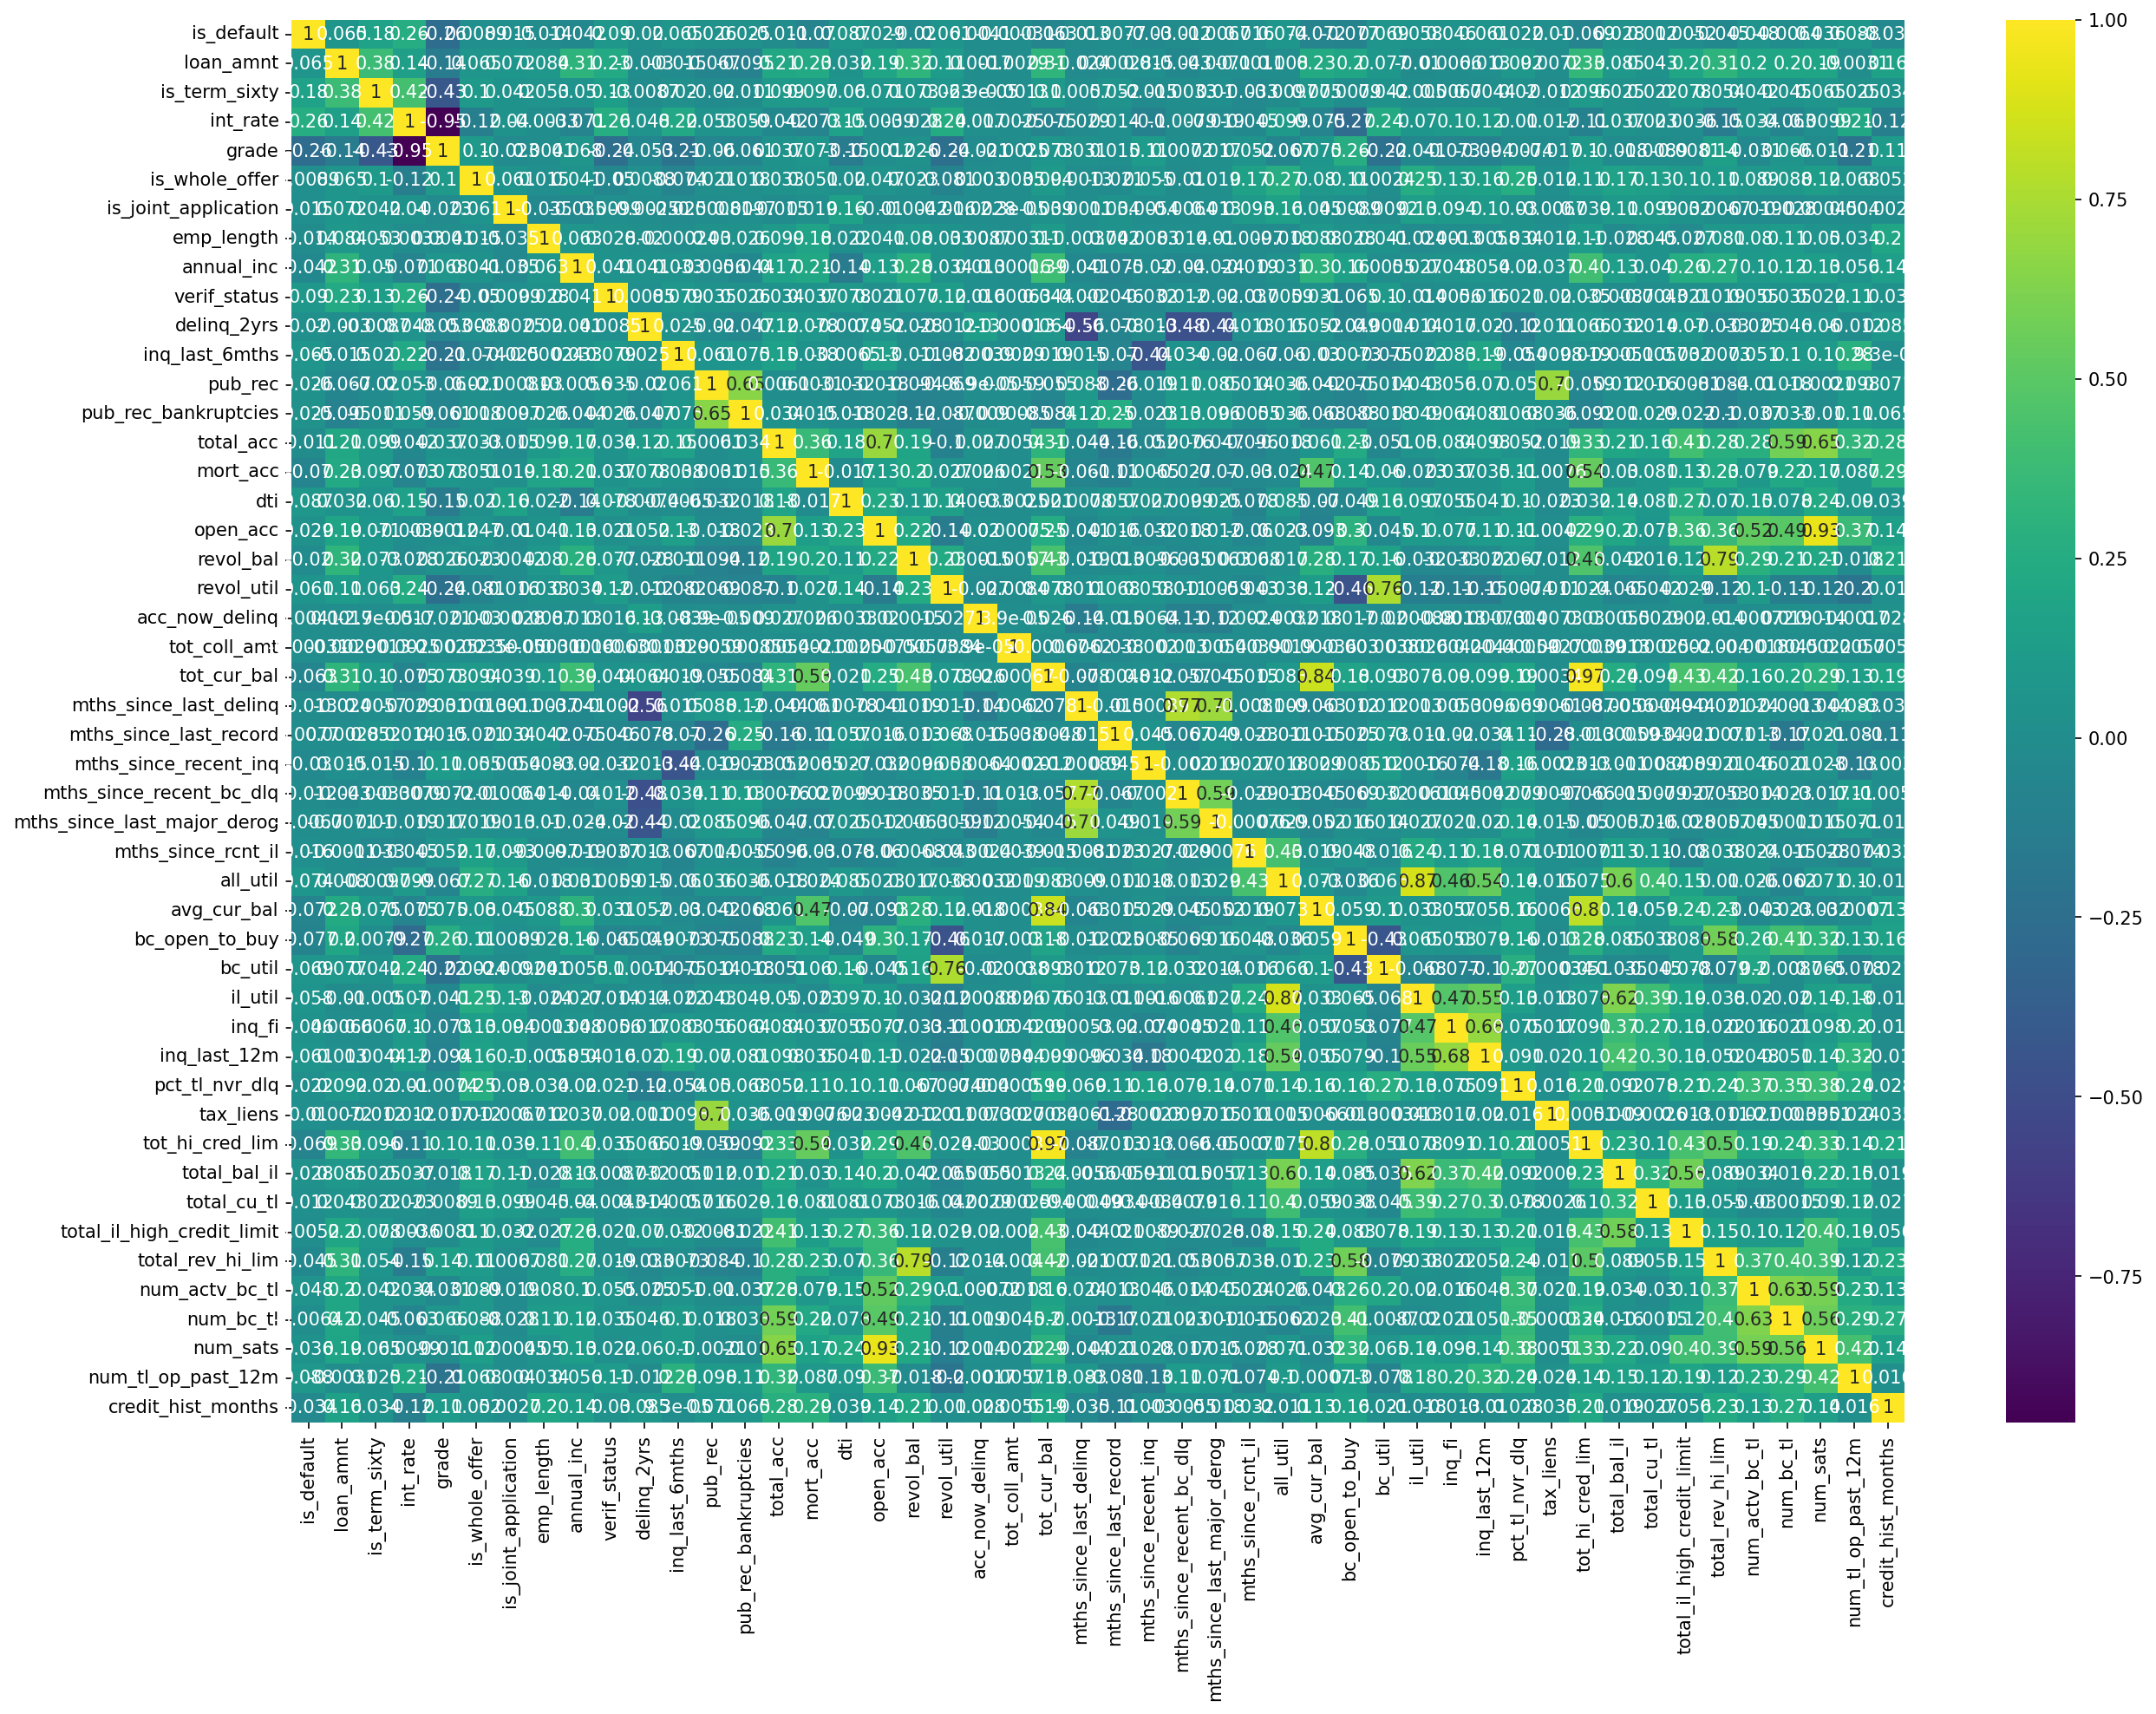

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(20,14), dpi= 150)
sns.heatmap(df.loc[:, [col for col in df.columns if col not in cat_features]].corr(), annot=True, cmap='viridis')
plt.savefig("EDA_graphs/correlation_heatmap.png", dpi=150)

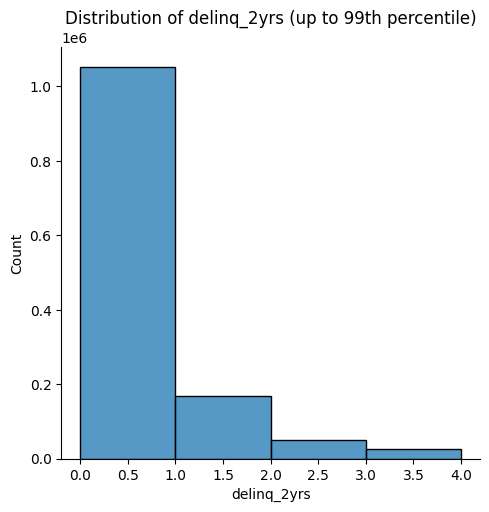

In [32]:
colvar = "delinq_2yrs"
binsvar = 4
upper_limit = df[colvar].quantile(0.99)

sns.displot(data=df[df[colvar] <= upper_limit], x=colvar, bins=binsvar)
plt.title(f"Distribution of {colvar} (up to 99th percentile)")

plt.savefig(f'EDA_graphs/{colvar} distribution', dpi=300)
plt.show()

# 3. Modelling

In [20]:
counts = df['addr_state'].value_counts()
idx = counts[counts.lt(5000)].index

df.loc[df['addr_state'].isin(idx), 'addr_state'] = 'Others'

df = df.drop(columns=['tot_hi_cred_lim', 'grade', 'avg_cur_bal', 'num_sats'])

In [21]:
df['addr_state'].value_counts()

addr_state
CA        191036
TX        106677
NY        106387
FL         92620
IL         50030
NJ         46885
PA         44117
OH         42438
GA         42032
VA         36852
NC         36615
Others     35068
MI         34128
AZ         31716
MD         30224
MA         30007
CO         28859
WA         28362
MN         23242
IN         21020
MO         20563
TN         19667
NV         19652
CT         19063
WI         17138
AL         16130
OR         15965
SC         15477
LA         15021
KY         12439
OK         11846
KS         10892
UT          9785
AR          9708
NM          7158
HI          6568
MS          6316
NH          6243
RI          5692
Name: count, dtype: int64

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303638 entries, 0 to 1303637
Data columns (total 47 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   is_default                   1303638 non-null  int64  
 1   loan_amnt                    1303638 non-null  int64  
 2   is_term_sixty                1303638 non-null  int64  
 3   purpose                      1303638 non-null  object 
 4   int_rate                     1303638 non-null  float64
 5   is_whole_offer               1303638 non-null  int64  
 6   is_joint_application         1303638 non-null  int64  
 7   emp_length                   1303638 non-null  float64
 8   home_ownership               1303638 non-null  object 
 9   annual_inc                   1303638 non-null  int64  
 10  verif_status                 1303638 non-null  int64  
 11  addr_state                   1303638 non-null  object 
 12  delinq_2yrs                  1303638 non-n

In [23]:

from sklearn.preprocessing import OneHotEncoder

categorical_columns = df.select_dtypes(include=['object']).columns

encoder = OneHotEncoder(sparse_output=False)

encoded_data = encoder.fit_transform(df[categorical_columns])

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(categorical_columns)
)

df1 = pd.concat(
    [df.drop(columns=categorical_columns), encoded_df],
    axis=1
)

In [24]:
# sampling to drastically reduce computing
df2 = df1.sample(n=200000, random_state=42)
df2

,is_default,loan_amnt,is_term_sixty,int_rate,is_whole_offer,is_joint_application,emp_length,annual_inc,verif_status,delinq_2yrs,inq_last_6mths,pub_rec,pub_rec_bankruptcies,total_acc,mort_acc,dti,open_acc,revol_bal,revol_util,acc_now_delinq,tot_coll_amt,tot_cur_bal,mths_since_last_delinq,mths_since_last_record,mths_since_recent_inq,mths_since_recent_bc_dlq,mths_since_last_major_derog,mths_since_rcnt_il,all_util,bc_open_to_buy,bc_util,il_util,inq_fi,inq_last_12m,pct_tl_nvr_dlq,tax_liens,total_bal_il,total_cu_tl,total_il_high_credit_limit,total_rev_hi_lim,num_actv_bc_tl,num_bc_tl,num_tl_op_past_12m,credit_hist_months,purpose_car,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_house,purpose_major_purchase,purpose_medical,purpose_moving,purpose_other,purpose_renewable_energy,purpose_small_business,purpose_vacation,purpose_wedding,home_ownership_ANY,home_ownership_MORTGAGE,home_ownership_NONE,home_ownership_OTHER,home_ownership_OWN,home_ownership_RENT,addr_state_AL,addr_state_AR,addr_state_AZ,addr_state_CA,addr_state_CO,addr_state_CT,addr_state_FL,addr_state_GA,addr_state_HI,addr_state_IL,addr_state_IN,addr_state_KS,addr_state_KY,addr_state_LA,addr_state_MA,addr_state_MD,addr_state_MI,addr_state_MN,addr_state_MO,addr_state_MS,addr_state_NC,addr_state_NH,addr_state_NJ,addr_state_NM,addr_state_NV,addr_state_NY,addr_state_OH,addr_state_OK,addr_state_OR,addr_state_Others,addr_state_PA,addr_state_RI,addr_state_SC,addr_state_TN,addr_state_TX,addr_state_UT,addr_state_VA,addr_state_WA,addr_state_WI
896352,0,10000,0,15.88,0,0,10.0,78000,0,1,1,0,0,30,0,5.89,17,11656,23.6,0,0,11656,9.0,NaN,4,9.0,43.0,0,0,31078,27.2,0,0,0,93.0,0,0,0,0,53300,5,19,1,162,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1186414,0,3600,0,11.99,1,0,2.0,86000,0,1,1,0,0,60,4,21.06,22,18069,38.7,0,0,262748,22.0,NaN,3,NaN,32.0,0,0,22031,39.8,0,0,0,98.3,0,0,0,54124,46700,6,22,4,302,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1267756,0,16000,0,12.87,0,0,10.0,65000,2,0,0,0,0,15,0,11.52,5,7290,93.5,0,0,0,NaN,NaN,0,NaN,NaN,0,0,0,0.0,0,0,0,0.0,0,0,0,0,0,0,0,0,156,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
101017,1,6800,0,12.79,1,0,6.0,36000,1,2,1,0,0,44,0,6.03,17,2953,43.4,0,0,120528,18.0,NaN,4,23.0,23.0,6,96,904,46.8,101,1,1,85.0,0,117575,0,114210,6800,2,7,3,226,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
82212,0,5075,0,23.99,0,0,3.0,52000,1,1,1,3,0,28,6,22.18,10,6360,46.8,0,9473,121734,9.0,62.0,5,9.0,44.0,6,50,2235,67.6,51,0,2,71.4,0,11189,0,21829,13600,2,9,5,468,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
863306,0,15000,1,16.20,0,0,10.0,43000,2,0,1,1,1,31,3,11.13,11,10090,65.5,

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler

x = df2.drop(columns=['is_default'])
y = df2['is_default']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, stratify = y, random_state=42)

# For standard scaler
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled  = scaler.transform(x_test)

x_train_scaled = pd.DataFrame(x_train_scaled, columns=x.columns, index=x_train.index)
x_test_scaled  = pd.DataFrame(x_test_scaled,  columns=x.columns, index=x_test.index)

# # For minmax scaler
# scaler1 = MinMaxScaler()
# x_train_scaled1 = scaler1.fit_transform(x_train)
# x_test_scaled1 = scaler1.transform(x_test)

# x_train_scaled1 = pd.DataFrame(x_train_scaled1, columns=x.columns, index=x_train.index)
# x_test_scaled1  = pd.DataFrame(x_test_scaled1,  columns=x.columns, index=x_test.index)

In [75]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"\n[A] scale_pos_weight = {spw:.3f}")



[A] scale_pos_weight = 3.946


In [27]:

from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, RocCurveDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score

# metrics
from sklearn.metrics import roc_auc_score, f1_score


In [28]:

# # hyperparameter tuning ~20 minutes runtime for 2500 fits

# param_grid = {
#     'n_estimators': [200, 300],
#     'max_depth': [3, 5, 7],             # very important
#     'min_child_weight': [3, 5, 7],
#     'subsample': [0.6, 0.8, 1.0],
#     'colsample_bytree': [0.6, 0.8, 1.0],
#     'learning_rate': [0.01, 0.1, 0.3]   # very important
# }

# # Create XGBoost classifier
# xgb = XGBClassifier(random_state=42) # default values

# # Perform grid search
# grid_search = GridSearchCV(estimator=xgb, param_grid=param_grid, cv=5, n_jobs=-1, verbose=5, scoring='roc_auc')
# grid_search.fit(x_train, y_train)

# # print best parameters
# print(f"Best parameters: {grid_search.best_params_}")
# print(f"Best score: {grid_search.best_score_}")

In [76]:
parameters = dict(
    n_estimators=200,
    max_depth=5,
    min_child_weight=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8, 
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

model_a = XGBClassifier(scale_pos_weight=spw, **parameters)
model_a.fit(x_train_scaled, y_train)

model_b = XGBClassifier(scale_pos_weight=spw, **parameters)
model_b.fit(x_train_scaled, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

In [77]:
threshold = 0.2
for name, model in [("A (scale_pos_weight)", model_a)]:
    proba = model.predict_proba(x_test_scaled)[:, 1]
    pred  = model.predict(x_test_scaled)
    auc   = roc_auc_score(y_test, proba)
    f1    = f1_score(y_test, pred)
    print(f"  {name}: AUC={auc:.4f}, F1={f1:.4f}")
    
for name, model in [("B (scale_pos_weight)", model_b)]:
    proba1 = model.predict_proba(x_test_scaled)[:, 1]

    pred1  = (proba1>=threshold).astype(int)
    auc   = roc_auc_score(y_test, proba1)
    f1    = f1_score(y_test, pred1)
    print(f"  {name}: AUC={auc:.4f}, F1={f1:.4f}")

  A (scale_pos_weight): AUC=0.7247, F1=0.4409
  B (scale_pos_weight): AUC=0.7247, F1=0.3618


              precision    recall  f1-score   support

 non_default     0.8861    0.6553    0.7534     31913
     default     0.3292    0.6675    0.4409      8087

    accuracy                         0.6578     40000
   macro avg     0.6076    0.6614    0.5972     40000
weighted avg     0.7735    0.6578    0.6903     40000



<Figure size 640x480 with 0 Axes>

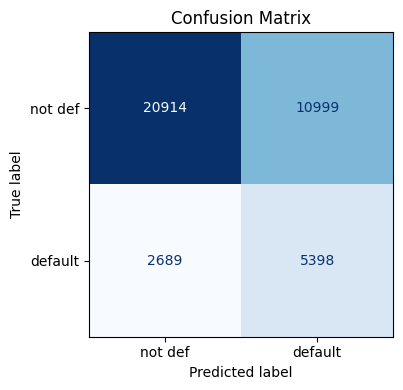

In [78]:
model = model_a

#predictions on the untouched test set

y_proba = model.predict_proba(x_test_scaled)[:, 1]
y_pred = model.predict(x_test_scaled)
print(classification_report(y_test, y_pred, target_names=["non_default", "default"], digits=4))

# confusion matrix
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["not def", "default"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix")
plt.tight_layout()

plt.show()

              precision    recall  f1-score   support

 non_default     0.9652    0.1268    0.2242     31913
     default     0.2218    0.9819    0.3618      8087

    accuracy                         0.2997     40000
   macro avg     0.5935    0.5544    0.2930     40000
weighted avg     0.8149    0.2997    0.2520     40000



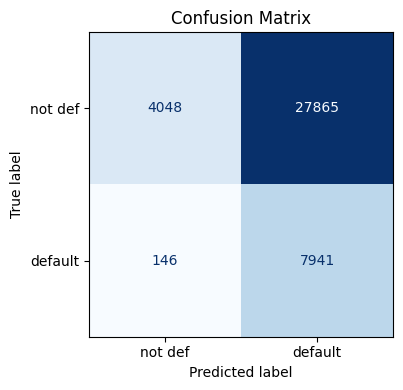

In [32]:
model1 = model_b

#predictions on the untouched test set

y_proba1 = model1.predict_proba(x_test_scaled)[:, 1]
y_pred1  = (y_proba1>=threshold).astype(int)
print(classification_report(y_test, y_pred1, target_names=["non_default", "default"], digits=4))

# confusion matrix
cm1 = confusion_matrix(y_test, y_pred1)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm1, display_labels=["not def", "default"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix")
plt.tight_layout()

plt.show()

c:\Users\Asus Tuf\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



waterfall for test row 17 (true positive)


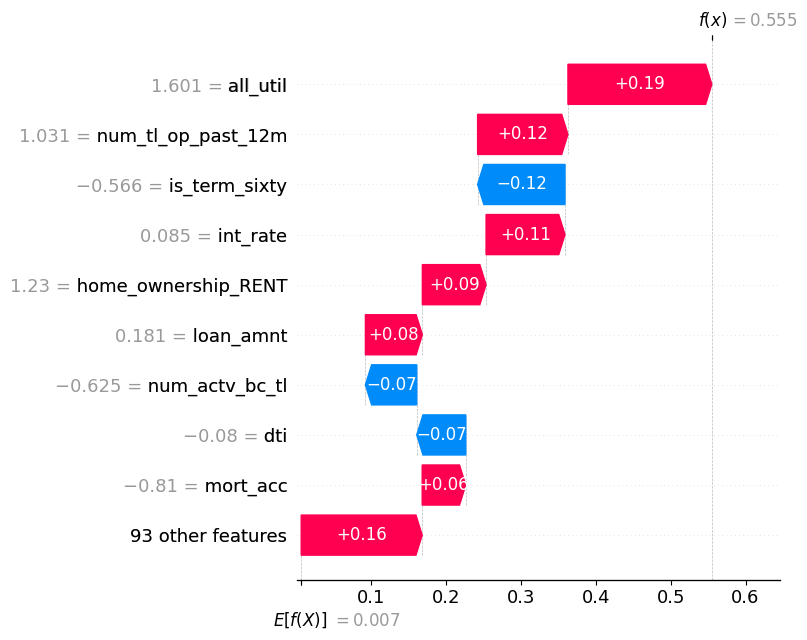

In [33]:
import shap
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(x_test_scaled)
tp_mask = (y_test.values == 1) & (y_pred == 1)
tp_idx  = np.where(tp_mask)[0][0] 

print(f"\nwaterfall for test row {tp_idx} (true positive)")
plt.figure()
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[tp_idx],
        base_values=explainer.expected_value,
        data=x_test_scaled.iloc[tp_idx],
        feature_names=list(x_test_scaled.columns),
    ),
    show=False,
)
plt.tight_layout()
plt.show()

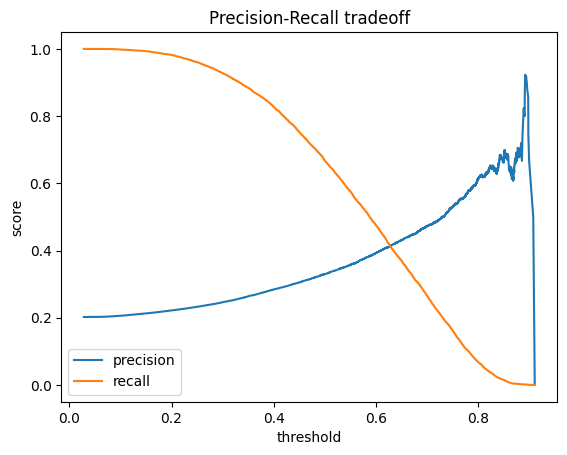

best F1 threshold: 0.529


In [34]:

from sklearn.metrics import precision_recall_curve

prec, rec, thr = precision_recall_curve(y_test, y_proba)

plt.plot(thr, prec[:-1], label="precision")
plt.plot(thr, rec[:-1], label="recall")
plt.xlabel("threshold")
plt.ylabel("score")
plt.title("Precision-Recall tradeoff")
plt.legend()
plt.show()

f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_thr = thr[f1s.argmax()]
print(f"best F1 threshold: {best_thr:.3f}")

In [35]:
def confusion_costs(y_true, y_pred, cost_fn, profit_tn, cost_fp=0):
    # class 1 = default = positive
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    n = tp + fn + fp + tn

    naive = tp*cost_fn - fn*cost_fn - fp*cost_fp + tn*profit_tn
    v = (tn*profit_tn - fn*cost_fn) / (tn + fn)

    return {
        "tp": tp, "fn": fn, "fp": fp, "tn": tn,
        "naive_total": naive, "naive_per_loan": naive/n,
        "recycled_per_loan": v,
    }

print(confusion_costs(y_test, y_pred, cost_fn=9719, profit_tn=2400))
print(confusion_costs(y_test, y_pred1, cost_fn=9719, profit_tn=2400))

{'tp': np.int64(5398), 'fn': np.int64(2689), 'fp': np.int64(10999), 'tn': np.int64(20914), 'naive_total': np.int64(76522371), 'naive_per_loan': np.float64(1913.059275), 'recycled_per_loan': np.float64(1019.3284328263356)}
{'tp': np.int64(7941), 'fn': np.int64(146), 'fp': np.int64(27865), 'tn': np.int64(4048), 'naive_total': np.int64(85474805), 'naive_per_loan': np.float64(2136.870125), 'recycled_per_loan': np.float64(1978.1177873152121)}


In [36]:
from joblib import dump, load


dump(model_a, 'ML_models/model_balanced.joblib')
dump(model_b, 'ML_models/model_recall.joblib')

['ML_models/model_recall.joblib']